# 03 · Regresión logística desde cero

Semana 3. Primero un ejemplo 2D sintético (para ver la frontera de decisión) y después el dataset real *Breast Cancer Wisconsin* (incluido en scikit-learn, sin descarga).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(0)
plt.rcParams["figure.figsize"] = (6, 4)

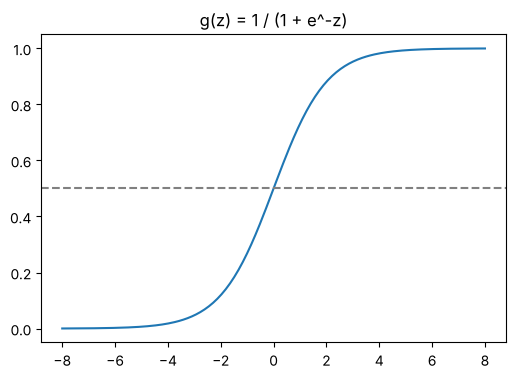

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-8, 8, 200)
plt.plot(z, sigmoid(z)); plt.axhline(0.5, ls="--", c="gray"); plt.title("g(z) = 1 / (1 + e^-z)"); plt.show()

## 1. Coste logístico y gradiente

In [3]:
def compute_cost(X, y, w, b):
    f = sigmoid(X @ w + b)
    eps = 1e-12  # avoid log(0)
    return -(y * np.log(f + eps) + (1 - y) * np.log(1 - f + eps)).mean()

def compute_gradient(X, y, w, b):
    err = sigmoid(X @ w + b) - y
    return X.T @ err / X.shape[0], err.mean()

def gradient_descent(X, y, w, b, alpha, iters):
    hist = []
    for _ in range(iters):
        dw, db = compute_gradient(X, y, w, b)
        w, b = w - alpha * dw, b - alpha * db
        hist.append(compute_cost(X, y, w, b))
    return w, b, hist

def predict(X, w, b, thr=0.5):
    return (sigmoid(X @ w + b) >= thr).astype(int)

## 2. Ejemplo 2D: horas de estudio y horas de sueño → aprobar

w = [0.835 1.093] b = -9.958  accuracy = 0.9


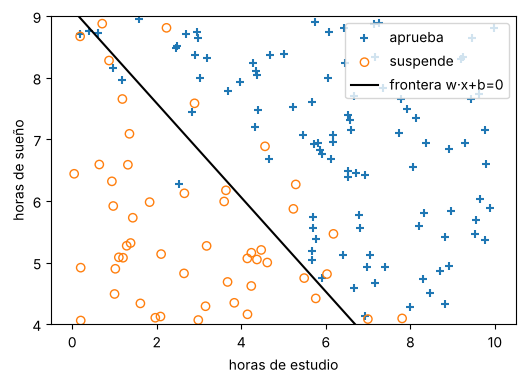

In [4]:
m = 150
X2 = np.column_stack([np.random.uniform(0, 10, m), np.random.uniform(4, 9, m)])
y2 = (0.9 * X2[:, 0] + 1.2 * X2[:, 1] - 11 + np.random.normal(0, 1, m) > 0).astype(float)
w2, b2, h2 = gradient_descent(X2, y2, np.zeros(2), 0.0, alpha=0.1, iters=5000)
print("w =", w2.round(3), "b =", round(b2, 3), " accuracy =", (predict(X2, w2, b2) == y2).mean())
xs = np.linspace(0, 10, 50)
plt.scatter(*X2[y2 == 1].T, marker="+", label="aprueba"); plt.scatter(*X2[y2 == 0].T, marker="o", facecolors="none", edgecolors="C1", label="suspende")
plt.plot(xs, -(w2[0] * xs + b2) / w2[1], "k", label="frontera w·x+b=0"); plt.ylim(4, 9)
plt.xlabel("horas de estudio"); plt.ylabel("horas de sueño"); plt.legend(); plt.show()

## 3. Dataset real: cáncer de mama (569 casos, 30 características)

accuracy train 0.988 · test 0.965


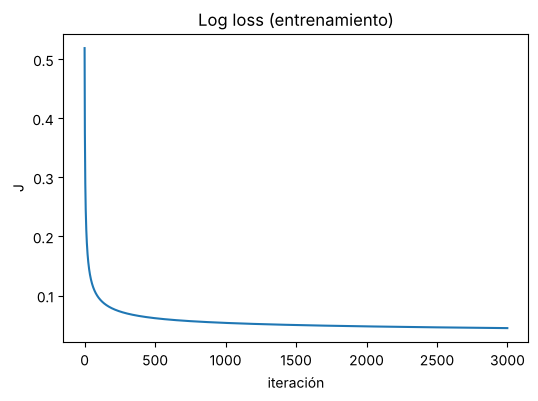

In [5]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
data = load_breast_cancer()
Xtr, Xte, ytr, yte = train_test_split(data.data, data.target, test_size=0.25, random_state=0, stratify=data.target)
mu, sd = Xtr.mean(0), Xtr.std(0)
Xtr_n, Xte_n = (Xtr - mu) / sd, (Xte - mu) / sd   # normalize with TRAIN stats only
w, b, h = gradient_descent(Xtr_n, ytr, np.zeros(Xtr.shape[1]), 0.0, alpha=0.1, iters=3000)
print(f"accuracy train {(predict(Xtr_n, w, b) == ytr).mean():.3f} · test {(predict(Xte_n, w, b) == yte).mean():.3f}")
plt.plot(h); plt.xlabel("iteración"); plt.ylabel("J"); plt.title("Log loss (entrenamiento)"); plt.show()

## 4. Comparación con scikit-learn

In [6]:
from sklearn.linear_model import LogisticRegression
sk = LogisticRegression(C=1e6, max_iter=10000).fit(Xtr_n, ytr)  # C huge ≈ no regularization
print(f"sklearn test accuracy {sk.score(Xte_n, yte):.3f}")

sklearn test accuracy 0.944
